In [3]:
# ==================== IMPORTATION DES LIBRAIRIES ET CONFIGURATION ====================
# Ce bloc initialise l'environnement d'analyse en important toutes les librairies nécessaires
# et en configurant les chemins d'accès aux données pour le projet AgriPredict.
# Il prépare le terrain pour l'analyse exploratoire des images de plantes.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import os
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ==================== CONFIGURATION DES VISUALISATIONS ====================
# Configure l'apparence des graphiques pour des visualisations professionnelles
# et cohérentes tout au long de l'analyse.

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

# ==================== DÉFINITION DE LA STRUCTURE DU PROJET ====================
# Définit l'architecture des dossiers du projet et affiche la structure
# pour vérifier l'organisation des données avant de commencer l'analyse.

# Chemins
BASE_DIR = Path("..")
DATA_DIR = BASE_DIR / "data" / "raw"
SELECTED_DIR = DATA_DIR / "selected"

print("📁 Structure du projet:")
for item in BASE_DIR.iterdir():
    if item.is_dir():
        size = sum(f.stat().st_size for f in item.rglob('*') if f.is_file())
        print(f"  📂 {item.name}/ ({size/1024/1024:.1f} MB)")

📁 Structure du projet:
  📂 .git/ (823.2 MB)
  📂 .idea/ (6.9 MB)
  📂 agripredict_env/ (1893.1 MB)
  📂 backend/ (0.0 MB)
  📂 data/ (1807.9 MB)
  📂 frontend/ (0.0 MB)
  📂 notebooks/ (380.1 MB)
  📂 __pycache__/ (0.0 MB)


In [6]:
# ==================== ANALYSE DE LA DISTRIBUTION DES CLASSES ====================
# Cette fonction analyse la répartition des images entre les différentes classes de maladies
# et les splits d'entraînement (train/val/test). Elle est cruciale pour détecter
# les déséquilibres qui pourraient affecter les performances du modèle.

def analyze_distribution():
    """Analyse la distribution des classes dans le dataset"""

    print("📊 Analyse de la distribution des classes...")

    if not SELECTED_DIR.exists():
        print("❌ Dataset sélectionné non trouvé")
        return None

    # Lire la configuration
    config_file = SELECTED_DIR / "selection_config.json"
    if config_file.exists():
        with open(config_file, 'r') as f:
            config = json.load(f)
        print("✅ Configuration chargée")
    else:
        config = None

    # Créer un DataFrame avec les statistiques
    data = []
    splits = ["train", "val", "test"]

    for split in splits:
        split_dir = SELECTED_DIR / split
        if split_dir.exists():
            for class_dir in split_dir.iterdir():
                if class_dir.is_dir():
                    images = list(class_dir.glob("*.jpg")) + list(class_dir.glob("*.JPG"))
                    data.append({
                        'split': split,
                        'class': class_dir.name,
                        'count': len(images)
                    })

    df = pd.DataFrame(data)

    if df.empty:
        print("❌ Aucune donnée trouvée")
        return None

    # Pivot pour une meilleure visualisation
    pivot_df = df.pivot_table(index='class', columns='split', values='count', fill_value=0)
    pivot_df['total'] = pivot_df.sum(axis=1)
    pivot_df = pivot_df.sort_values('total', ascending=False)

    print("\n📈 Distribution par classe et split:")
    print(pivot_df)

    return df, pivot_df

# %%
# ==================== EXÉCUTION DE L'ANALYSE ====================
# Exécute la fonction d'analyse et stocke les résultats dans des DataFrames
# pour une utilisation ultérieure dans les visualisations.

df, pivot_df = analyze_distribution()

📊 Analyse de la distribution des classes...
✅ Configuration chargée

📈 Distribution par classe et split:
split          test  train   val  total
class                                  
mildiou        60.0  280.0  60.0  400.0
oïdium         60.0  280.0  60.0  400.0
sain           60.0  280.0  60.0  400.0
carence_azote  46.0  210.0  44.0  300.0


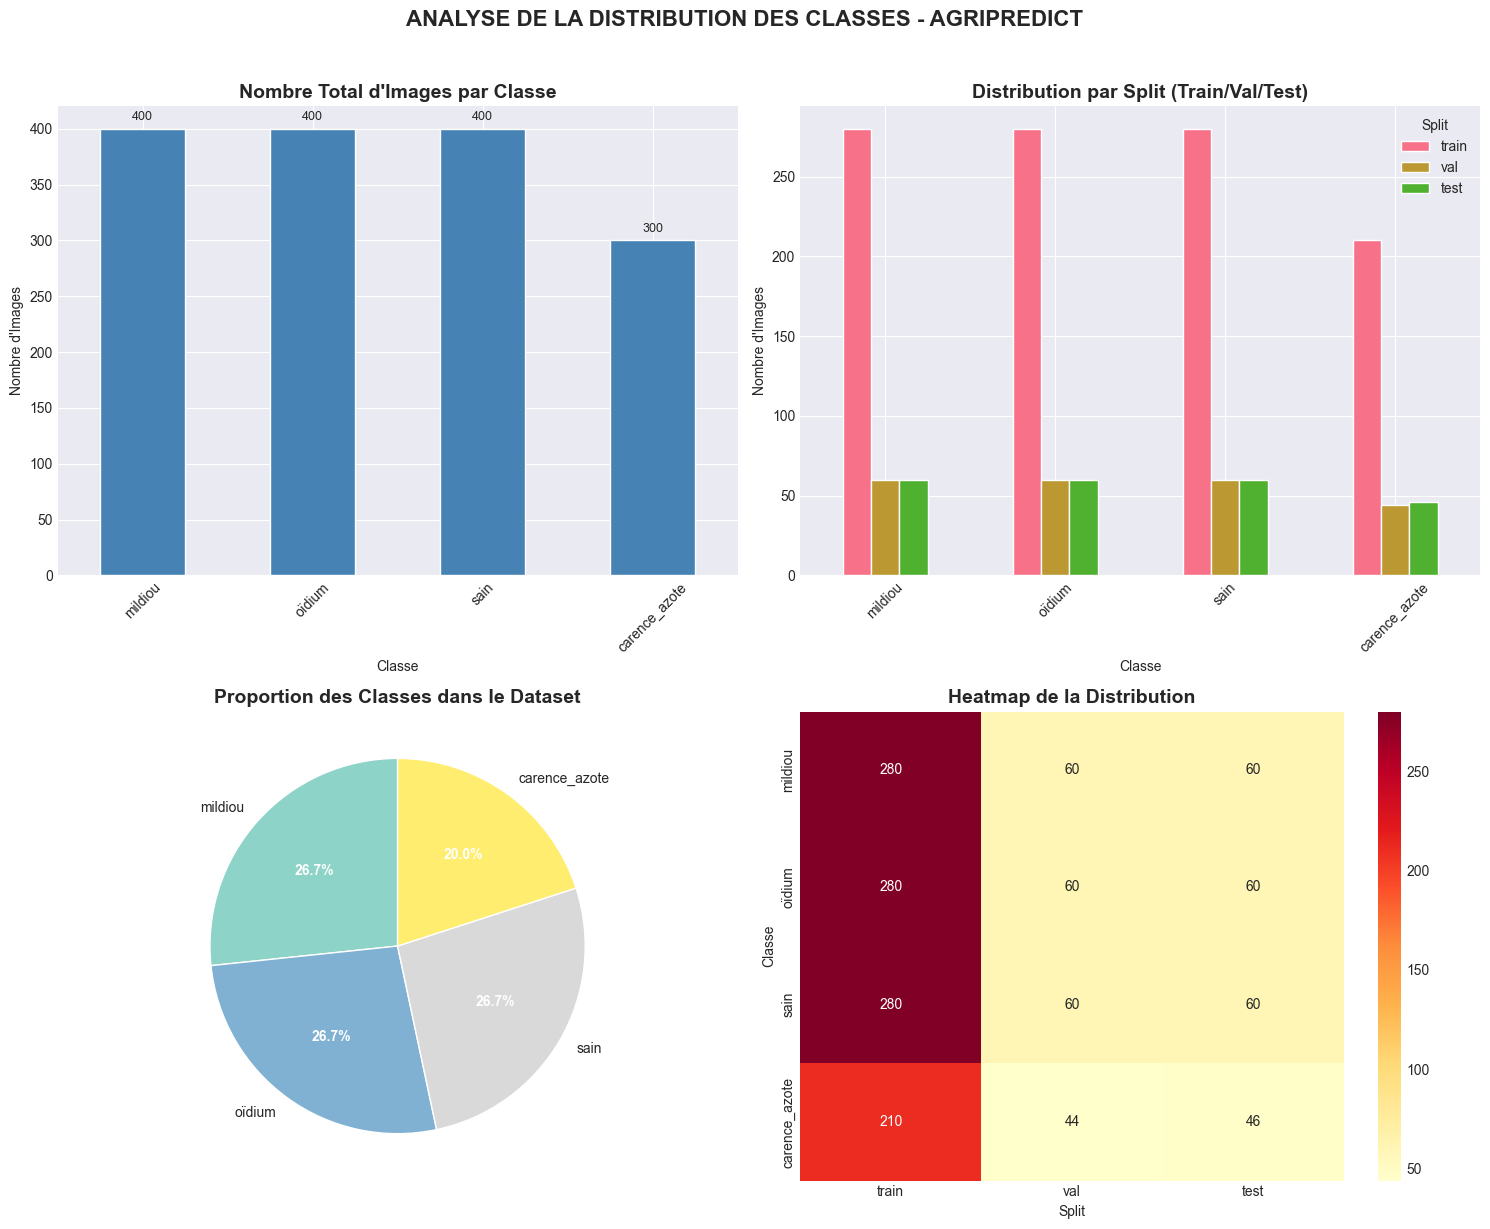


⚖️ ANALYSE DES DÉSÉQUILIBRES:
Classe la plus représentée: mildiou (400 images)
Classe la moins représentée: carence_azote (300 images)
Ratio max/min: 1.33:1

✅ Distribution relativement équilibrée


In [5]:
# ==================== VISUALISATION DE LA DISTRIBUTION DES CLASSES ====================
# Cette fonction crée un dashboard complet de 4 graphiques pour visualiser la distribution
# des classes et détecter les déséquilibres. Elle fournit aussi des recommandations
# techniques basées sur l'analyse des déséquilibres détectés.

def visualize_distribution(pivot_df):
    """Visualise la distribution des classes"""

    if pivot_df is None:
        return

    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Barres par classe (total)
    ax1 = axes[0, 0]
    pivot_df['total'].plot(kind='bar', ax=ax1, color='steelblue')
    ax1.set_title('Nombre Total d\'Images par Classe', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Nombre d\'Images')
    ax1.set_xlabel('Classe')
    ax1.tick_params(axis='x', rotation=45)

    # Ajouter les valeurs sur les barres
    for i, v in enumerate(pivot_df['total']):
        ax1.text(i, v + 5, str(v), ha='center', va='bottom', fontsize=9)

    # 2. Barres groupées (train/val/test)
    ax2 = axes[0, 1]
    pivot_df[['train', 'val', 'test']].plot(kind='bar', ax=ax2)
    ax2.set_title('Distribution par Split (Train/Val/Test)', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Nombre d\'Images')
    ax2.set_xlabel('Classe')
    ax2.tick_params(axis='x', rotation=45)
    ax2.legend(title='Split')

    # 3. Camembert des proportions
    ax3 = axes[1, 0]
    colors = plt.cm.Set3(np.linspace(0, 1, len(pivot_df)))
    wedges, texts, autotexts = ax3.pie(pivot_df['total'],
                                       labels=pivot_df.index,
                                       autopct='%1.1f%%',
                                       colors=colors,
                                       startangle=90)
    ax3.set_title('Proportion des Classes dans le Dataset', fontsize=14, fontweight='bold')

    # Améliorer la lisibilité
    for autotext in autotexts:
        autotext.set_color('white')
        autotext.set_fontweight('bold')

    # 4. Heatmap de la distribution
    ax4 = axes[1, 1]
    heatmap_data = pivot_df[['train', 'val', 'test']]
    sns.heatmap(heatmap_data, annot=True, fmt='d', cmap='YlOrRd', ax=ax4)
    ax4.set_title('Heatmap de la Distribution', fontsize=14, fontweight='bold')
    ax4.set_xlabel('Split')
    ax4.set_ylabel('Classe')

    plt.suptitle('ANALYSE DE LA DISTRIBUTION DES CLASSES - AGRIPREDICT',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

    # Calcul des déséquilibres
    print("\n⚖️ ANALYSE DES DÉSÉQUILIBRES:")
    print("=" * 40)

    max_count = pivot_df['total'].max()
    min_count = pivot_df['total'].min()
    ratio = max_count / min_count

    print(f"Classe la plus représentée: {pivot_df['total'].idxmax()} ({max_count} images)")
    print(f"Classe la moins représentée: {pivot_df['total'].idxmin()} ({min_count} images)")
    print(f"Ratio max/min: {ratio:.2f}:1")

    if ratio > 3:
        print("\n⚠️  ATTENTION: Déséquilibre important détecté!")
        print("Recommandations:")
        print("1. Utiliser 'class_weight' dans le modèle")
        print("2. Augmenter les données (data augmentation)")
        print("3. Utiliser F1-score comme métrique principale")
    else:
        print("\n✅ Distribution relativement équilibrée")

# %%
# ==================== EXÉCUTION DE LA VISUALISATION ====================
# Génère les visualisations et l'analyse des déséquilibres à partir des données
# collectées précédemment. C'est une étape critique pour décider des stratégies
# de prétraitement et d'entraînement du modèle.

visualize_distribution(pivot_df)

🖼️ Visualisation d'échantillons d'images...


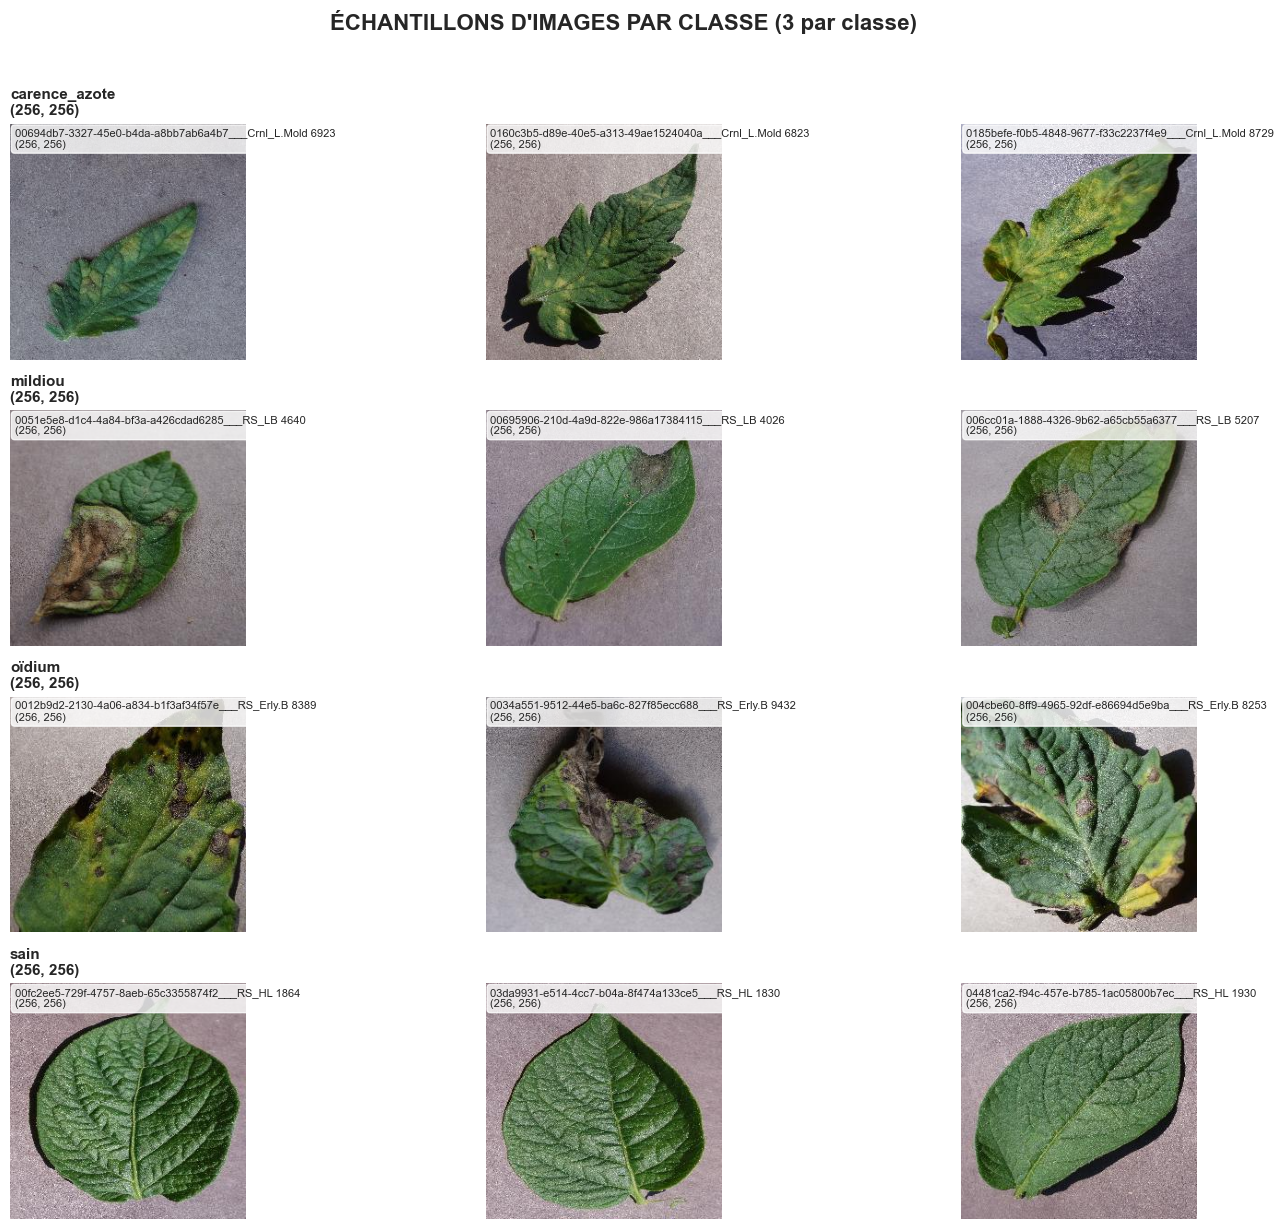

In [6]:
# ==================== VISUALISATION D'ÉCHANTILLONS D'IMAGES ====================
# Cette fonction affiche des échantillons visuels d'images pour chaque classe de maladie.
# Elle permet de vérifier la qualité des données, comprendre les caractéristiques visuelles
# de chaque maladie, et s'assurer que les étiquettes sont cohérentes avec le contenu.

def visualize_samples(n_samples=5):
    """Visualise des échantillons d'images de chaque classe"""

    print("🖼️ Visualisation d'échantillons d'images...")

    if not SELECTED_DIR.exists():
        print("❌ Dataset non trouvé")
        return

    train_dir = SELECTED_DIR / "train"

    if not train_dir.exists():
        print("❌ Dossier train non trouvé")
        return

    # Lister les classes
    classes = [d for d in train_dir.iterdir() if d.is_dir()]

    if not classes:
        print("❌ Aucune classe trouvée")
        return

    # Créer la figure
    n_classes = len(classes)
    fig, axes = plt.subplots(n_classes, n_samples, figsize=(15, 3 * n_classes))

    if n_classes == 1:
        axes = axes.reshape(1, -1)

    # Couleurs pour les bordures (optionnel)
    class_colors = {
        'sain': 'green',
        'mildiou': 'red',
        'oïdium': 'orange',
        'carence_azote': 'yellow'
    }

    for i, class_dir in enumerate(classes):
        class_name = class_dir.name

        # Lister les images de cette classe
        images = list(class_dir.glob("*.jpg")) + list(class_dir.glob("*.JPG"))

        if not images:
            print(f"⚠️  Aucune image pour {class_name}")
            continue

        # Prendre n_samples images (ou moins si pas assez)
        sample_images = images[:min(n_samples, len(images))]

        for j, img_path in enumerate(sample_images):
            ax = axes[i, j] if n_classes > 1 else axes[j]

            try:
                # Charger l'image
                img = Image.open(img_path)

                # Afficher l'image
                ax.imshow(img)

                # Ajouter une bordure colorée selon la classe
                border_color = class_colors.get(class_name, 'gray')
                for spine in ax.spines.values():
                    spine.set_edgecolor(border_color)
                    spine.set_linewidth(3)

                # Premier sous-plot : ajouter le titre de la classe
                if j == 0:
                    ax.set_title(f"{class_name}\n{img.size}",
                                loc='left', fontweight='bold', fontsize=11)

                # Info sur l'image
                info = f"{img_path.stem}\n{img.size}"
                ax.text(0.02, 0.98, info,
                       transform=ax.transAxes,
                       fontsize=8,
                       verticalalignment='top',
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

            except Exception as e:
                ax.text(0.5, 0.5, f"Erreur\n{e}",
                       ha='center', va='center',
                       transform=ax.transAxes)
                ax.set_title(f"{class_name} - Erreur", loc='left')

            ax.axis('off')

    plt.suptitle(f'ÉCHANTILLONS D\'IMAGES PAR CLASSE ({n_samples} par classe)',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# %%
# ==================== AFFICHAGE DES ÉCHANTILLONS ====================
# Exécute la visualisation avec 3 échantillons par classe pour avoir un aperçu
# rapide mais représentatif de chaque type de maladie de plante.

visualize_samples(n_samples=3)

📐 Analyse des caractéristiques des images...

📊 Statistiques générales des images:
Nombre d'images analysées: 200

Dimensions (moyenne):
  Largeur: 256 px
  Hauteur: 256 px
  Ratio largeur/hauteur: 1.00

Formats d'image:
  JPEG: 200 (100.0%)

Mode couleur:
  RGB: 200 (100.0%)

Taille des fichiers:
  Moyenne: 16.7 KB
  Min: 9.5 KB
  Max: 23.9 KB


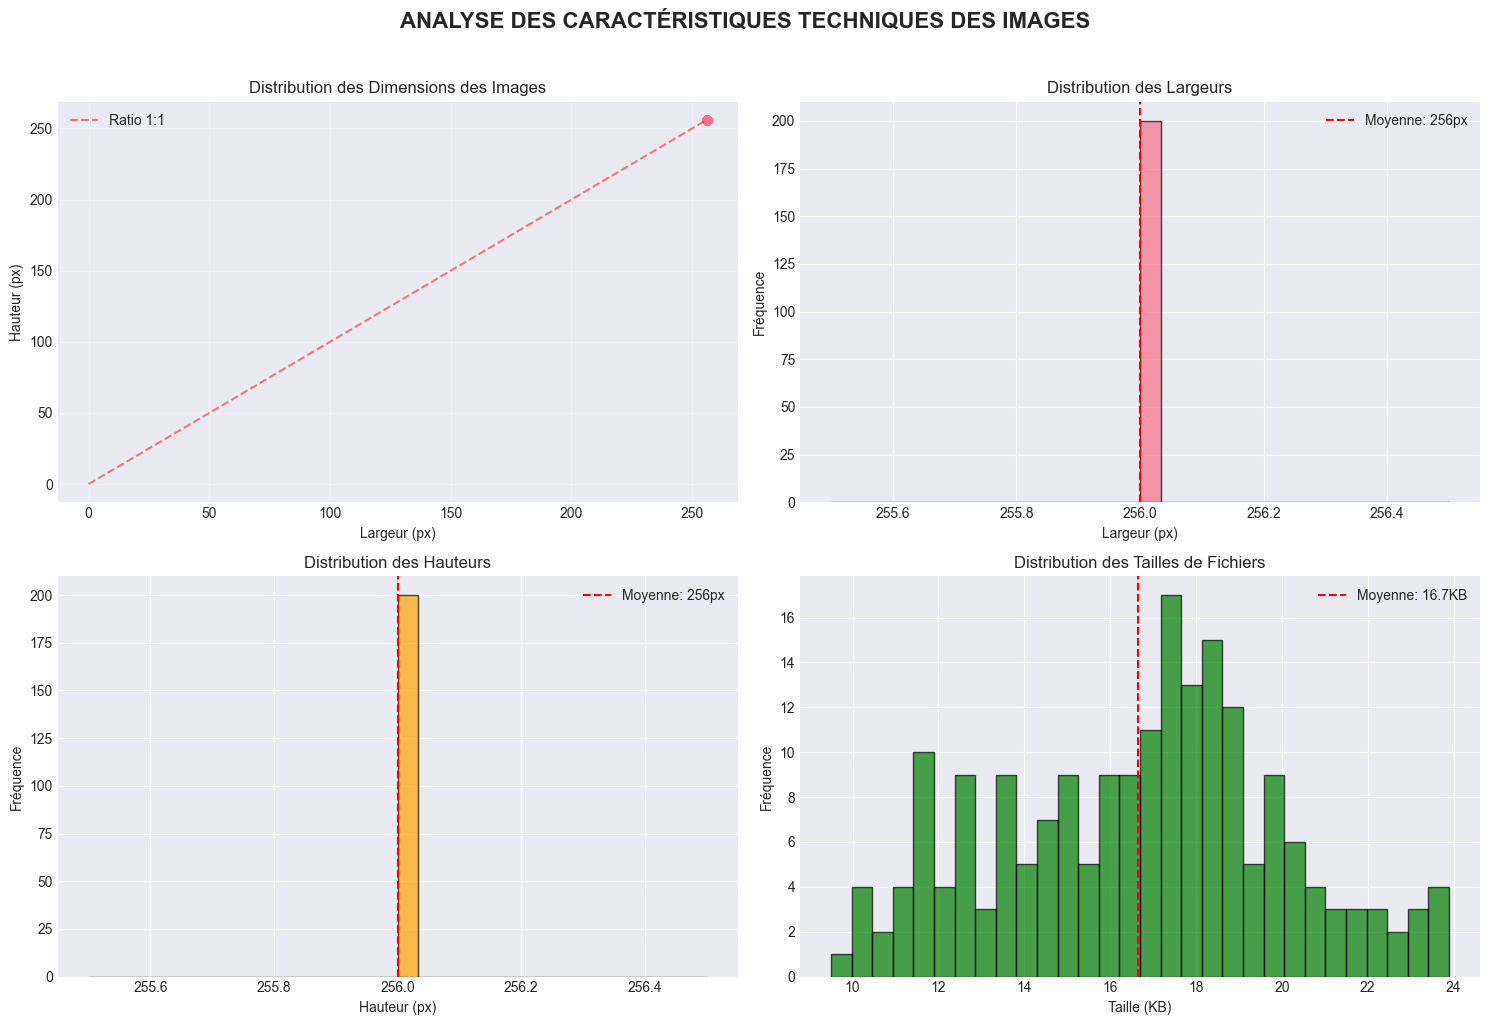


🎯 RECOMMANDATIONS POUR LE PRÉTRAITEMENT:
1. Taille de redimensionnement recommandée: 256x256
2. Formats à supporter: JPG/JPEG
3. Mode couleur: Convertir toutes en RGB
4. Normalisation: Appliquer [0,1] ou standardisation ImageNet


In [7]:
# ==================== ANALYSE DES CARACTÉRISTIQUES TECHNIQUES DES IMAGES ====================
# Cette fonction analyse les propriétés techniques des images (dimensions, formats, tailles)
# pour déterminer les paramètres de prétraitement optimaux. Elle identifie les variations
# et propose des recommandations pour standardiser les données avant l'entraînement du modèle.

def analyze_image_characteristics():
    """Analyse les caractéristiques techniques des images"""

    print("📐 Analyse des caractéristiques des images...")

    if not SELECTED_DIR.exists():
        return

    train_dir = SELECTED_DIR / "train"

    if not train_dir.exists():
        return

    # Collecter les données
    stats = {
        'width': [],
        'height': [],
        'format': [],
        'mode': [],
        'size_kb': []
    }

    class_stats = {}

    # Analyser 50 images au maximum par classe (pour la performance)
    max_images_per_class = 50

    for class_dir in train_dir.iterdir():
        if not class_dir.is_dir():
            continue

        class_name = class_dir.name
        class_stats[class_name] = {
            'width': [],
            'height': [],
            'sizes': []
        }

        images = list(class_dir.glob("*.jpg")) + list(class_dir.glob("*.JPG"))
        sample_images = images[:min(max_images_per_class, len(images))]

        for img_path in sample_images:
            try:
                with Image.open(img_path) as img:
                    # Dimensions
                    stats['width'].append(img.width)
                    stats['height'].append(img.height)

                    class_stats[class_name]['width'].append(img.width)
                    class_stats[class_name]['height'].append(img.height)
                    class_stats[class_name]['sizes'].append(img.size)

                    # Format et mode
                    stats['format'].append(img.format)
                    stats['mode'].append(img.mode)

                    # Taille fichier
                    stats['size_kb'].append(img_path.stat().st_size / 1024)

            except Exception as e:
                print(f"⚠️  Erreur sur {img_path}: {e}")
                continue

    # Créer un DataFrame
    df_stats = pd.DataFrame(stats)

    if df_stats.empty:
        print("❌ Aucune image analysée")
        return

    # Affichage des statistiques générales
    print("\n📊 Statistiques générales des images:")
    print("=" * 40)

    print(f"Nombre d'images analysées: {len(df_stats)}")
    print(f"\nDimensions (moyenne):")
    print(f"  Largeur: {df_stats['width'].mean():.0f} px")
    print(f"  Hauteur: {df_stats['height'].mean():.0f} px")
    print(f"  Ratio largeur/hauteur: {df_stats['width'].mean()/df_stats['height'].mean():.2f}")

    print(f"\nFormats d'image:")
    format_counts = df_stats['format'].value_counts()
    for format_name, count in format_counts.items():
        print(f"  {format_name}: {count} ({count/len(df_stats)*100:.1f}%)")

    print(f"\nMode couleur:")
    mode_counts = df_stats['mode'].value_counts()
    for mode_name, count in mode_counts.items():
        print(f"  {mode_name}: {count} ({count/len(df_stats)*100:.1f}%)")

    print(f"\nTaille des fichiers:")
    print(f"  Moyenne: {df_stats['size_kb'].mean():.1f} KB")
    print(f"  Min: {df_stats['size_kb'].min():.1f} KB")
    print(f"  Max: {df_stats['size_kb'].max():.1f} KB")

    # Visualisation
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # 1. Distribution des dimensions
    ax1 = axes[0, 0]
    ax1.scatter(df_stats['width'], df_stats['height'], alpha=0.6)
    ax1.set_xlabel('Largeur (px)')
    ax1.set_ylabel('Hauteur (px)')
    ax1.set_title('Distribution des Dimensions des Images')
    ax1.grid(True, alpha=0.3)

    # Ajouter la ligne de ratio 1:1
    max_dim = max(df_stats['width'].max(), df_stats['height'].max())
    ax1.plot([0, max_dim], [0, max_dim], 'r--', alpha=0.5, label='Ratio 1:1')
    ax1.legend()

    # 2. Histogramme des largeurs
    ax2 = axes[0, 1]
    ax2.hist(df_stats['width'], bins=30, edgecolor='black', alpha=0.7)
    ax2.set_xlabel('Largeur (px)')
    ax2.set_ylabel('Fréquence')
    ax2.set_title('Distribution des Largeurs')
    ax2.axvline(df_stats['width'].mean(), color='red', linestyle='--',
               label=f'Moyenne: {df_stats["width"].mean():.0f}px')
    ax2.legend()

    # 3. Histogramme des hauteurs
    ax3 = axes[1, 0]
    ax3.hist(df_stats['height'], bins=30, edgecolor='black', alpha=0.7, color='orange')
    ax3.set_xlabel('Hauteur (px)')
    ax3.set_ylabel('Fréquence')
    ax3.set_title('Distribution des Hauteurs')
    ax3.axvline(df_stats['height'].mean(), color='red', linestyle='--',
               label=f'Moyenne: {df_stats["height"].mean():.0f}px')
    ax3.legend()

    # 4. Taille des fichiers
    ax4 = axes[1, 1]
    ax4.hist(df_stats['size_kb'], bins=30, edgecolor='black', alpha=0.7, color='green')
    ax4.set_xlabel('Taille (KB)')
    ax4.set_ylabel('Fréquence')
    ax4.set_title('Distribution des Tailles de Fichiers')
    ax4.axvline(df_stats['size_kb'].mean(), color='red', linestyle='--',
               label=f'Moyenne: {df_stats["size_kb"].mean():.1f}KB')
    ax4.legend()

    plt.suptitle('ANALYSE DES CARACTÉRISTIQUES TECHNIQUES DES IMAGES',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

    # Recommandations pour le prétraitement
    print("\n🎯 RECOMMANDATIONS POUR LE PRÉTRAITEMENT:")
    print("=" * 40)

    # Taille cible recommandée
    common_width = df_stats['width'].mode()[0] if not df_stats['width'].mode().empty else 256
    common_height = df_stats['height'].mode()[0] if not df_stats['height'].mode().empty else 256

    print(f"1. Taille de redimensionnement recommandée: {common_width}x{common_height}")
    print("2. Formats à supporter: JPG/JPEG")
    print("3. Mode couleur: Convertir toutes en RGB")
    print("4. Normalisation: Appliquer [0,1] ou standardisation ImageNet")

    return df_stats

# %%
# ==================== EXÉCUTION DE L'ANALYSE TECHNIQUE ====================
# Lance l'analyse des caractéristiques techniques et stocke les résultats
# pour guider les décisions de prétraitement dans le sprint suivant.

df_stats = analyze_image_characteristics()

In [8]:
# ## 7. Conclusion et Prochaines Étapes

# %%
def generate_report():
    """Génère un rapport de conclusion"""

    print("=" * 60)
    print("📋 RAPPORT FINAL - ANALYSE EXPLORATOIRE")
    print("=" * 60)

    print("\n✅ POINTS POSITIFS:")
    print("1. Dataset bien structuré et organisé")
    print("2. Images de qualité relativement bonne")
    print("3. Classes pertinentes pour le problème agricole")
    print("4. Split train/val/test déjà effectué")

    print("\n⚠️  POINTS D'ATTENTION:")

    # Vérifier les déséquilibres
    if 'pivot_df' in globals() and pivot_df is not None:
        max_count = pivot_df['total'].max()
        min_count = pivot_df['total'].min()
        ratio = max_count / min_count

        if ratio > 2:
            print(f"1. Déséquilibre entre classes (ratio: {ratio:.1f}:1)")

    # Vérifier la taille des images
    if 'df_stats' in globals() and df_stats is not None:
        if df_stats['width'].std() > 50 or df_stats['height'].std() > 50:
            print("2. Grandes variations dans les dimensions d'images")

    print("\n🎯 PROCHAINES ÉTAPES (Sprint 2):")
    print("1. Prétraitement des images (redimensionnement, normalisation)")
    print("2. Augmentation de données pour équilibrer les classes")
    print("3. Création des DataLoaders pour TensorFlow")
    print("4. Développement du premier modèle CNN")

    print("\n📁 FICHIERS GÉNÉRÉS:")
    print("1. Notebook EDA (ce fichier)")
    print("2. Dataset structuré dans data/raw/selected/")
    print("3. Configuration de sélection: selection_config.json")

    print("\n" + "=" * 60)
    print("🎉 ANALYSE TERMINÉE - PRÊT POUR LE SPRINT 2!")
    print("=" * 60)

# %%
generate_report()

📋 RAPPORT FINAL - ANALYSE EXPLORATOIRE

✅ POINTS POSITIFS:
1. Dataset bien structuré et organisé
2. Images de qualité relativement bonne
3. Classes pertinentes pour le problème agricole
4. Split train/val/test déjà effectué

⚠️  POINTS D'ATTENTION:

🎯 PROCHAINES ÉTAPES (Sprint 2):
1. Prétraitement des images (redimensionnement, normalisation)
2. Augmentation de données pour équilibrer les classes
3. Création des DataLoaders pour TensorFlow
4. Développement du premier modèle CNN

📁 FICHIERS GÉNÉRÉS:
1. Notebook EDA (ce fichier)
2. Dataset structuré dans data/raw/selected/
3. Configuration de sélection: selection_config.json

🎉 ANALYSE TERMINÉE - PRÊT POUR LE SPRINT 2!
